Reexecução em ambiente virtual isolado em 21/10/2026. Python e dependências registrados nos arquivos de ambiente. Dados fixados na revisão 25fa86bc199935c3a745e70a1e11e48c9f676082. Usado n_jobs=1 por restrição de processos do ambiente; os tempos não são comparáveis aos da execução anterior.

# Experimento: Árvore de Decisão vs. Random Forest vs. XGBoost

**Projeto:** Preditor de degradação de rede  
**Objetivo:** comparar três classificadores usando uma base pública de telemetria de rede.  
**Base:** [LocalNet-Dynamics — Hugging Face](https://huggingface.co/datasets/ezharjan/LocalNetDynamics)  
**Licença indicada na página:** MIT. Consulte a página da base antes de redistribuir os dados.

## Decisão metodológica importante

A base possui medições de RTT/latência, jitter, perda de pacotes e rótulos de referência. O rótulo `label_high_latency` é derivado da própria latência (`rtt_avg_ms`). Para evitar **vazamento de dados**, não usaremos `rtt_avg_ms` como entrada do modelo. Neste experimento, usaremos `jitter_ms` e `packet_loss_pct` para classificar se a medição foi marcada como de latência alta.

Isso é uma comparação experimental dos modelos, não uma validação definitiva do preditor do grupo: o conjunto de dados é de uma rede residencial e os rótulos são gerados por regras, não por uma anotação independente de especialistas. Para uma versão futura mais fiel ao projeto, o grupo pode definir um alvo futuro (por exemplo, degradação nos próximos minutos) e usar somente medições anteriores como entradas.


## 1. Instalar e importar bibliotecas

Execute esta célula no Google Colab ou em um ambiente Python com acesso à internet. O pacote `xgboost` é necessário para o terceiro modelo.


In [1]:
%pip -q install datasets==5.1.0 xgboost==3.4.1 scikit-learn==1.9.1 pandas==3.0.6 numpy==2.5.4 matplotlib==3.11.2 seaborn==0.13.2


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Registrar o ambiente da nova execução
Esta célula registra as versões reais após a instalação. A execução original não registrou versões exatas. Execute tudo e preserve os dois arquivos gerados junto dos novos resultados.


In [2]:
import sys, json, platform, importlib.metadata as metadata
from pathlib import Path
pacotes = ["datasets", "xgboost", "scikit-learn", "pandas", "numpy", "matplotlib", "seaborn"]
versoes = {nome: metadata.version(nome) for nome in pacotes}
ambiente = {"python": sys.version, "plataforma": platform.platform(), "bibliotecas": versoes}
Path("ambiente_execucao.json").write_text(json.dumps(ambiente, indent=2, ensure_ascii=False), encoding="utf-8")
Path("requirements-execucao.txt").write_text("\n".join(f"{nome}=={versao}" for nome, versao in versoes.items()) + "\n", encoding="utf-8")
print(json.dumps(ambiente, indent=2, ensure_ascii=False))


{
  "python": "3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 22.1.3 ]",
  "plataforma": "Linux-6.18.55-x86_64-with-glibc2.39",
  "bibliotecas": {
    "datasets": "5.1.0",
    "xgboost": "3.4.1",
    "scikit-learn": "1.9.1",
    "pandas": "3.0.6",
    "numpy": "2.5.4",
    "matplotlib": "3.11.2",
    "seaborn": "0.13.2"
  }
}


In [3]:
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from xgboost import XGBClassifier

SEMENTE = 42
np.random.seed(SEMENTE)
print("Bibliotecas importadas.")

Bibliotecas importadas.


## 2. Baixar e conhecer a base

A base possui dezenas de milhares de observações. Primeiro verificamos os nomes das colunas e a distribuição do rótulo antes de treinar os modelos.


In [4]:
dataset = load_dataset("ezharjan/LocalNetDynamics", revision="25fa86bc199935c3a745e70a1e11e48c9f676082", split="train")
df = dataset.to_pandas()

print("Dimensões da base:", df.shape)
display(df[["jitter_ms", "packet_loss_pct", "label_high_latency"]].head())
print("\\nColunas disponíveis:")
print(df.columns.tolist())

Dimensões da base: (54617, 67)
\nColunas disponíveis:
['run_id', 'host_label', 'sample_index', 'timestamp_utc', 'timestamp_local', 'epoch_s', 'elapsed_s', 'link_type', 'gateway_ip', 'dns_server', 'target', 'collector_version', 'collector_os', 'interval_s', 'rtt_resolution_ms', 'date_local', 'hour_local', 'weekday_local', 'is_weekend', 'gap_before_s', 'rtt_min_ms', 'rtt_avg_ms', 'rtt_median_ms', 'rtt_max_ms', 'rtt_stddev_ms', 'jitter_ms', 'packets_sent', 'packets_received', 'packet_loss_pct', 'gateway_rtt_min_ms', 'gateway_rtt_avg_ms', 'gateway_rtt_max_ms', 'gateway_jitter_ms', 'gateway_packet_loss_pct', 'tcp_connect_min_ms', 'tcp_connect_median_ms', 'dns_resolve_ms', 'dns_recursive_ms', 'http_ms', 'http_status', 'wifi_ssid', 'wifi_signal_pct', 'wifi_rssi_dbm', 'wifi_rx_mbps', 'wifi_tx_mbps', 'wifi_channel', 'wifi_band_ghz', 'wifi_phy', 'download_mbps', 'upload_mbps', 'speedtest_ping_ms', 'download_loaded_latency_ms', 'upload_loaded_latency_ms', 'speedtest_server_id', 'speedtest_server'

,jitter_ms,packet_loss_pct,label_high_latency
0,0.667,0.0,0
1,0.500,10.0,0
2,0.889,0.0,0
3,0.889,0.0,0
4,58.000,0.0,1


## 3. Preparar os dados

- **Entradas (X):** `jitter_ms` e `packet_loss_pct`.
- **Alvo (y):** `label_high_latency` (0 = não marcado como latência alta; 1 = marcado como latência alta).
- A coluna `rtt_avg_ms` fica de fora porque é usada para construir o rótulo de latência alta. Incluí-la como entrada tornaria o teste circular.
- Linhas sem rótulo são removidas; valores ausentes nas entradas serão preenchidos com a mediana, calculada dentro do pipeline de cada modelo.


In [5]:
COLUNAS_X = ["jitter_ms", "packet_loss_pct"]
COLUNA_Y = "label_high_latency"

necessarias = COLUNAS_X + [COLUNA_Y]
faltantes = [c for c in necessarias if c not in df.columns]
if faltantes:
    raise ValueError(f"Colunas esperadas não encontradas na base: {faltantes}")

dados = df[necessarias].copy()
dados[COLUNAS_X] = dados[COLUNAS_X].apply(pd.to_numeric, errors="coerce")
dados[COLUNA_Y] = pd.to_numeric(dados[COLUNA_Y], errors="coerce")
dados = dados.dropna(subset=[COLUNA_Y])
dados = dados[dados[COLUNA_Y].isin([0, 1])]
dados[COLUNA_Y] = dados[COLUNA_Y].astype(int)

X = dados[COLUNAS_X]
y = dados[COLUNA_Y]

print("Total de linhas usadas:", len(dados))
print("\\nDistribuição do alvo:")
display(y.value_counts().rename(index={0: "Normal (0)", 1: "Latência alta (1)"}).to_frame("quantidade"))
display((y.value_counts(normalize=True) * 100).round(2).rename(index={0: "Normal (0)", 1: "Latência alta (1)"}).to_frame("percentual (%)"))

if y.nunique() < 2:
    raise ValueError("O alvo contém apenas uma classe; não é possível comparar classificadores.")

Total de linhas usadas: 54617
\nDistribuição do alvo:


,quantidade
label_high_latency,
Normal (0),51550
Latência alta (1),3067


,percentual (%)
label_high_latency,
Normal (0),94.38
Latência alta (1),5.62


## 4. Separar treino e teste

Usaremos 80% para treino e 20% para teste, com semente fixa e estratificação para manter aproximadamente a proporção das classes em ambos os conjuntos. O teste fica reservado para a avaliação final; a busca de hiperparâmetros ocorre somente nos dados de treino.


In [6]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEMENTE,
    stratify=y
)

print(f"Treino: {len(X_treino)} linhas")
print(f"Teste:  {len(X_teste)} linhas")
print("\\nProporção da classe positiva:")
print("Treino:", round(y_treino.mean() * 100, 2), "%")
print("Teste: ", round(y_teste.mean() * 100, 2), "%")

# Peso para a classe positiva, útil se houver desbalanceamento.
positivos = int((y_treino == 1).sum())
negativos = int((y_treino == 0).sum())
peso_positivo = negativos / max(positivos, 1)
print("scale_pos_weight calculado para XGBoost:", round(peso_positivo, 3))

Treino: 43693 linhas
Teste:  10924 linhas
\nProporção da classe positiva:
Treino: 5.62 %
Teste:  5.61 %
scale_pos_weight calculado para XGBoost: 16.805


## 5. Treinar e ajustar os três modelos

A busca de hiperparâmetros usa validação cruzada estratificada de 3 partes **somente dentro do conjunto de treino**. O critério de seleção é F1 da classe positiva, pois a classe de latência alta pode ser menos frequente que a normal. Os três modelos recebem quatro combinações candidatas, para manter o esforço de ajuste simples e comparável.


In [7]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMENTE)

modelos = {
    "Árvore de Decisão": (
        DecisionTreeClassifier(random_state=SEMENTE, class_weight="balanced"),
        {
            "modelo__max_depth": [3, 8],
            "modelo__min_samples_leaf": [1, 5]
        }
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=SEMENTE, n_jobs=1, class_weight="balanced"),
        {
            "modelo__n_estimators": [100, 200],
            "modelo__max_depth": [8, None]
        }
    ),
    "XGBoost": (
        XGBClassifier(
            random_state=SEMENTE,
            eval_metric="logloss",
            n_jobs=1,
            scale_pos_weight=peso_positivo
        ),
        {
            "modelo__n_estimators": [100, 200],
            "modelo__max_depth": [3, 5],
            "modelo__learning_rate": [0.1]
        }
    )
}

resultados = []
modelos_treinados = {}
matrizes = {}

for nome, (estimador, grade) in modelos.items():
    pipeline = Pipeline([
        ("imputador", SimpleImputer(strategy="median")),
        ("modelo", estimador)
    ])
    busca = GridSearchCV(
        estimator=pipeline,
        param_grid=grade,
        scoring="f1",
        cv=cv,
        n_jobs=1,
        refit=True
    )

    inicio_treino = time.perf_counter()
    busca.fit(X_treino, y_treino)
    tempo_treino = time.perf_counter() - inicio_treino

    inicio_pred = time.perf_counter()
    previsoes = busca.predict(X_teste)
    tempo_predicao = time.perf_counter() - inicio_pred

    resultados.append({
        "Modelo": nome,
        "Acurácia": accuracy_score(y_teste, previsoes),
        "Precisão (classe 1)": precision_score(y_teste, previsoes, pos_label=1, zero_division=0),
        "Recall (classe 1)": recall_score(y_teste, previsoes, pos_label=1, zero_division=0),
        "F1 (classe 1)": f1_score(y_teste, previsoes, pos_label=1, zero_division=0),
        "F1 macro": f1_score(y_teste, previsoes, average="macro", zero_division=0),
        "Treino + ajuste (s)": tempo_treino,
        "Predição do teste (s)": tempo_predicao,
        "Melhores parâmetros": str(busca.best_params_)
    })
    modelos_treinados[nome] = busca.best_estimator_
    matrizes[nome] = confusion_matrix(y_teste, previsoes, labels=[0, 1])

    print(f"\n{nome}")
    print("Melhores parâmetros:", busca.best_params_)
    print(classification_report(
        y_teste, previsoes,
        labels=[0, 1],
        target_names=["Normal (0)", "Latência alta (1)"],
        zero_division=0
    ))

tabela_resultados = pd.DataFrame(resultados).sort_values("F1 (classe 1)", ascending=False)
display(tabela_resultados.round(4))


Árvore de Decisão
Melhores parâmetros: {'modelo__max_depth': 8, 'modelo__min_samples_leaf': 5}
                   precision    recall  f1-score   support

       Normal (0)       1.00      0.70      0.82     10311
Latência alta (1)       0.16      0.95      0.27       613

         accuracy                           0.71     10924
        macro avg       0.58      0.82      0.54     10924
     weighted avg       0.95      0.71      0.79     10924


Random Forest
Melhores parâmetros: {'modelo__max_depth': 8, 'modelo__n_estimators': 200}
                   precision    recall  f1-score   support

       Normal (0)       0.99      0.70      0.82     10311
Latência alta (1)       0.16      0.94      0.27       613

         accuracy                           0.71     10924
        macro avg       0.58      0.82      0.55     10924
     weighted avg       0.95      0.71      0.79     10924


XGBoost
Melhores parâmetros: {'modelo__learning_rate': 0.1, 'modelo__max_depth': 5, 'modelo__n_esti

,Modelo,Acurácia,Precisão (classe 1),Recall (classe 1),F1 (classe 1),F1 macro,Treino + ajuste (s),Predição do teste (s),Melhores parâmetros
1,Random Forest,0.7138,0.1572,0.9396,0.2693,0.5457,26.5181,0.0878,"{'modelo__max_depth': 8, 'modelo__n_estimators..."
0,Árvore de Decisão,0.7098,0.1562,0.9478,0.2682,0.5436,0.4935,0.0023,"{'modelo__max_depth': 8, 'modelo__min_samples_..."
2,XGBoost,0.7103,0.1549,0.9347,0.2658,0.5427,2.2190,0.0242,"{'modelo__learning_rate': 0.1, 'modelo__max_de..."


## 6. Matrizes de confusão

Na matriz, a classe 1 representa uma medição rotulada como latência alta. **Falso negativo**: a medição de latência alta foi classificada como normal. **Falso positivo**: uma medição normal recebeu um alerta de latência alta.


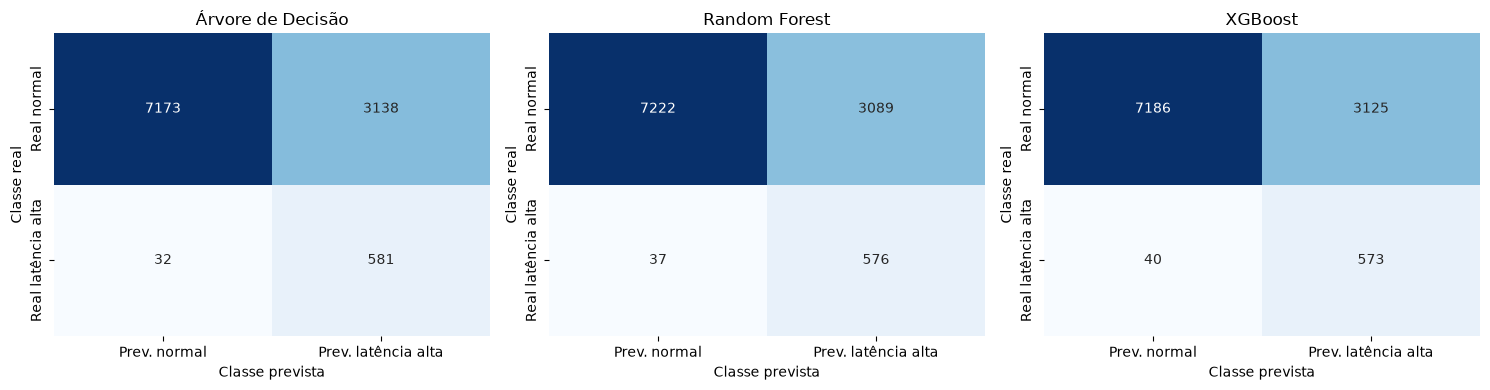

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nome, cm) in zip(axes, matrizes.items()):
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=["Prev. normal", "Prev. latência alta"],
        yticklabels=["Real normal", "Real latência alta"]
    )
    ax.set_title(nome)
    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe real")
plt.tight_layout()
plt.show()

## 7. Interpretabilidade: visualizar a Árvore de Decisão

A árvore abaixo é a melhor árvore encontrada na busca. Se ficar grande, a visualização será limitada a três níveis para facilitar a leitura; isso não altera o modelo usado na avaliação.


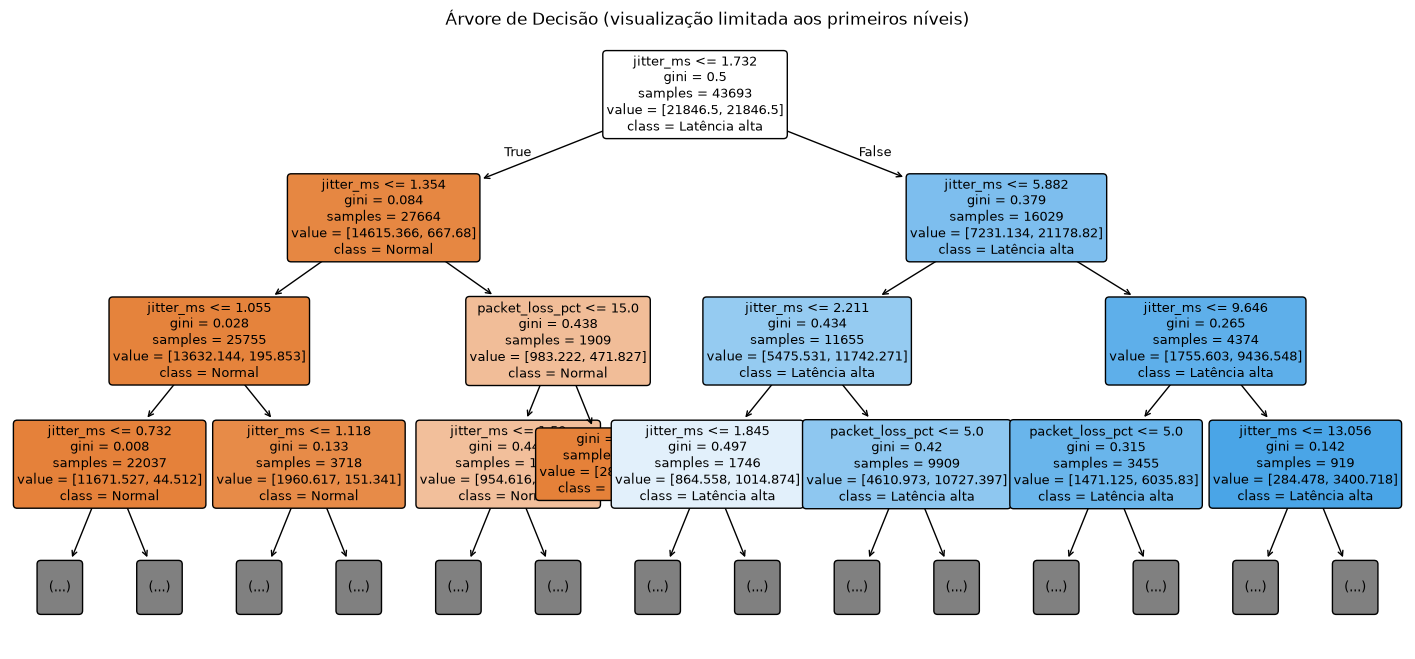

In [9]:
arvore = modelos_treinados["Árvore de Decisão"].named_steps["modelo"]
plt.figure(figsize=(18, 8))
plot_tree(
    arvore,
    feature_names=COLUNAS_X,
    class_names=["Normal", "Latência alta"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)
plt.title("Árvore de Decisão (visualização limitada aos primeiros níveis)")
plt.show()

## 8. Importância das entradas

A importância indica quanto cada atributo contribuiu para as divisões do modelo. Ela não demonstra causalidade e deve ser interpretada com cautela, especialmente quando atributos são correlacionados.


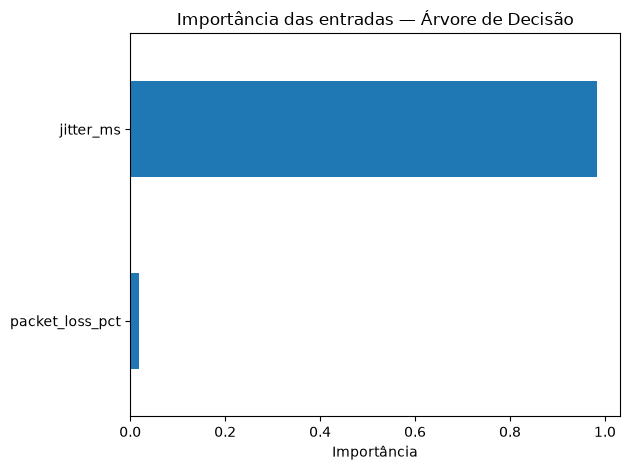

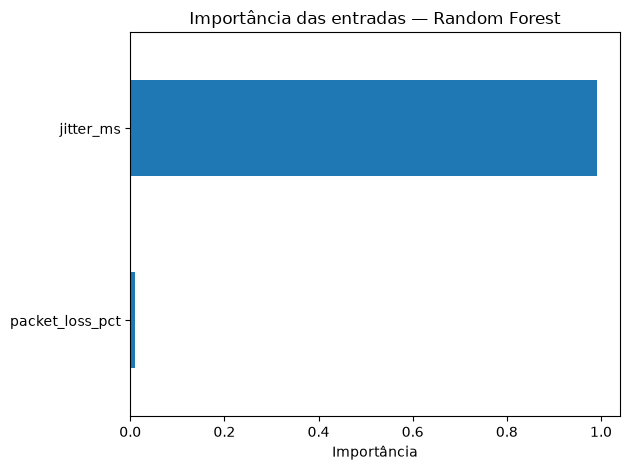

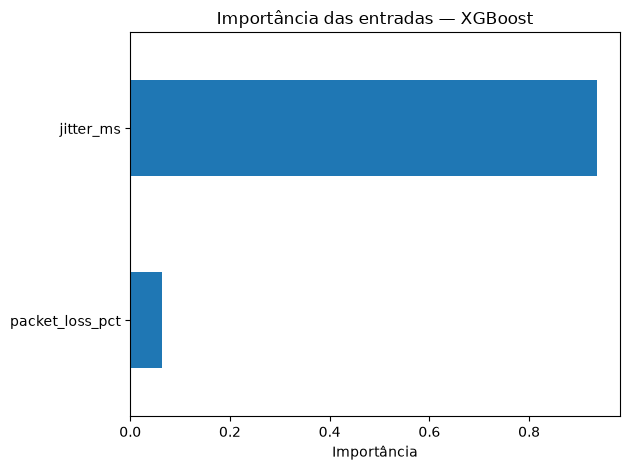

In [10]:
for nome in ["Árvore de Decisão", "Random Forest", "XGBoost"]:
    modelo = modelos_treinados[nome].named_steps["modelo"]
    if hasattr(modelo, "feature_importances_"):
        importancias = pd.Series(modelo.feature_importances_, index=COLUNAS_X).sort_values()
        ax = importancias.plot(kind="barh", title=f"Importância das entradas — {nome}")
        ax.set_xlabel("Importância")
        plt.tight_layout()
        plt.show()

## 9. Exportar resultados

Os arquivos abaixo podem ser anexados ao repositório do grupo. O CSV de resultados registra as métricas medidas nesta execução; não copie números antes de executar o notebook.


In [11]:
tabela_resultados.to_csv("resultados_modelos.csv", index=False, encoding="utf-8-sig")
print("Arquivo salvo: resultados_modelos.csv")

# Também salva a matriz de confusão de cada modelo em um único CSV.
linhas_cm = []
for nome, cm in matrizes.items():
    linhas_cm.append({
        "Modelo": nome,
        "Verdadeiro normal": int(cm[0, 0]),
        "Falso positivo": int(cm[0, 1]),
        "Falso negativo": int(cm[1, 0]),
        "Verdadeiro latência alta": int(cm[1, 1])
    })
pd.DataFrame(linhas_cm).to_csv("matrizes_confusao.csv", index=False, encoding="utf-8-sig")
print("Arquivo salvo: matrizes_confusao.csv")

Arquivo salvo: resultados_modelos.csv
Arquivo salvo: matrizes_confusao.csv


## 10. Como interpretar e escrever a conclusão

Preencha a conclusão **depois de executar** o notebook:

1. Qual modelo teve o maior F1 para a classe de latência alta?
2. Qual teve o maior recall? Isso importa porque um recall baixo significa que muitas situações de latência alta passaram despercebidas.
3. Qual foi o tempo de treino e de predição de cada modelo?
4. Qual modelo é mais fácil de explicar? A árvore única costuma ser mais interpretável; a floresta e o boosting combinam várias árvores.
5. O ganho de métricas compensa o custo de complexidade e latência?

### Limitações que precisam constar no artigo

- A base é de uma rede residencial específica; os resultados não garantem o mesmo desempenho em outras redes.
- Os rótulos são referências calculadas por regras com base nas medições, e não uma verdade absoluta independente.
- Este teste prevê o rótulo `label_high_latency` usando jitter e perda de pacotes; não usa RTT como entrada para evitar vazamento.
- Para avaliar previsão antecipada de degradação, o próximo experimento deve usar medições de janelas anteriores para prever uma classe futura, separando treino e teste temporalmente.
- O tempo medido depende do computador e do ambiente em que o notebook é executado.

### Referências

- Dataset LocalNet-Dynamics: https://huggingface.co/datasets/ezharjan/LocalNetDynamics
- Scikit-learn — Decision Trees: https://scikit-learn.org/stable/modules/tree.html
- Scikit-learn — Random Forests: https://scikit-learn.org/stable/modules/ensemble.html#forest
- XGBoost — documentação: https://xgboost.readthedocs.io/


# Parte 2 — Avaliação temporal e comparação

Esta parte complementa o experimento original. A divisão aleatória já executada acima permanece como referência.

**Cuidado:** o objetivo é classificar o rótulo contemporâneo `label_high_latency`, não prever falhas futuras. A entrada `rtt_avg_ms` continua excluída para evitar vazamento direto. A divisão temporal ordena medições por `timestamp_utc`, mantendo observações mais antigas no treino e mais recentes no teste. Isso não garante independência entre medições da mesma execução nem generalização a outras redes.

Os resultados temporais só estarão disponíveis após executar as células a seguir.


In [12]:
from sklearn.model_selection import TimeSeriesSplit

COLUNA_TEMPO = "timestamp_utc"
if COLUNA_TEMPO not in df.columns:
    raise ValueError("Não foi encontrada a coluna timestamp_utc.")

base_temporal = df[COLUNAS_X + [COLUNA_Y, COLUNA_TEMPO, "run_id"]].copy()
base_temporal[COLUNA_TEMPO] = pd.to_datetime(base_temporal[COLUNA_TEMPO], utc=True, errors="coerce")
base_temporal[COLUNAS_X] = base_temporal[COLUNAS_X].apply(pd.to_numeric, errors="coerce")
base_temporal[COLUNA_Y] = pd.to_numeric(base_temporal[COLUNA_Y], errors="coerce")
base_temporal = base_temporal.dropna(subset=[COLUNA_TEMPO, COLUNA_Y])
base_temporal = base_temporal[base_temporal[COLUNA_Y].isin([0, 1])]
base_temporal[COLUNA_Y] = base_temporal[COLUNA_Y].astype(int)
base_temporal = base_temporal.sort_values([COLUNA_TEMPO, "run_id"], kind="stable").reset_index(drop=True)

# O corte ocorre entre timestamps distintos para evitar que registros
# do mesmo instante apareçam simultaneamente em treino e teste.
corte = base_temporal[COLUNA_TEMPO].iloc[int(0.8 * len(base_temporal))]
treino_t = base_temporal[base_temporal[COLUNA_TEMPO] < corte]
teste_t = base_temporal[base_temporal[COLUNA_TEMPO] >= corte]
X_treino_t, y_treino_t = treino_t[COLUNAS_X], treino_t[COLUNA_Y]
X_teste_t, y_teste_t = teste_t[COLUNAS_X], teste_t[COLUNA_Y]

print("Corte temporal (UTC):", corte)
print("Treino:", len(treino_t), "| Teste:", len(teste_t))
print("Positivos no treino:", int(y_treino_t.sum()), "| Positivos no teste:", int(y_teste_t.sum()))
print("Execuções no treino:", treino_t.run_id.nunique(), "| no teste:", teste_t.run_id.nunique())
print("Execuções presentes em ambos:", len(set(treino_t.run_id) & set(teste_t.run_id)))
if y_treino_t.nunique() != 2 or y_teste_t.nunique() != 2:
    raise ValueError("A divisão temporal deixou treino ou teste sem uma das classes. É necessário rever o período de corte.")


Corte temporal (UTC): 2026-10-06 00:02:39+00:00
Treino: 43693 | Teste: 10924
Positivos no treino: 3061 | Positivos no teste: 6
Execuções no treino: 1 | no teste: 1
Execuções presentes em ambos: 1


## Treinar com validação cruzada temporal

Usamos a mesma grade de hiperparâmetros da primeira parte. Na validação temporal, cada divisão usa dados anteriores para treinar e posteriores para validar. O conjunto final de teste não é usado na escolha dos parâmetros.


In [13]:
# 'modelos' é o dicionário de estimadores e grades definido na primeira parte.
# Reconstruímos o peso do XGBoost a partir do treino temporal.
positivos_t = int(y_treino_t.sum())
negativos_t = int((y_treino_t == 0).sum())
peso_t = negativos_t / max(positivos_t, 1)

modelos_temporais_def = {}
for nome, (estimador, grade) in modelos.items():
    if nome == "XGBoost":
        estimador = XGBClassifier(
            random_state=SEMENTE, eval_metric="logloss",
            n_jobs=1, scale_pos_weight=peso_t
        )
    modelos_temporais_def[nome] = (estimador, grade)

cv_t = TimeSeriesSplit(n_splits=3)
resultados_t = []
matrizes_t = {}
modelos_t = {}

for nome, (estimador, grade) in modelos_temporais_def.items():
    pipeline = Pipeline([
        ("imputador", SimpleImputer(strategy="median")),
        ("modelo", estimador)
    ])
    busca = GridSearchCV(
        pipeline, grade, scoring="f1", cv=cv_t,
        n_jobs=1, refit=True, error_score="raise"
    )
    inicio = time.perf_counter()
    busca.fit(X_treino_t, y_treino_t)
    tempo_treino = time.perf_counter() - inicio

    inicio = time.perf_counter()
    pred = busca.predict(X_teste_t)
    tempo_pred = time.perf_counter() - inicio
    cm = confusion_matrix(y_teste_t, pred, labels=[0, 1])

    resultados_t.append({
        "Modelo": nome,
        "Acurácia": accuracy_score(y_teste_t, pred),
        "Precisão (classe 1)": precision_score(y_teste_t, pred, zero_division=0),
        "Recall (classe 1)": recall_score(y_teste_t, pred, zero_division=0),
        "F1 (classe 1)": f1_score(y_teste_t, pred, zero_division=0),
        "F1 macro": f1_score(y_teste_t, pred, average="macro", zero_division=0),
        "Falso positivo": int(cm[0, 1]),
        "Falso negativo": int(cm[1, 0]),
        "Verdadeiro negativo": int(cm[0, 0]),
        "Verdadeiro positivo": int(cm[1, 1]),
        "Treino + ajuste (s)": tempo_treino,
        "Predição do teste (s)": tempo_pred,
        "Melhores parâmetros": str(busca.best_params_)
    })
    matrizes_t[nome] = cm
    modelos_t[nome] = busca.best_estimator_
    print(nome, "— melhores parâmetros:", busca.best_params_)
    print(classification_report(y_teste_t, pred, labels=[0,1], zero_division=0))

tabela_temporal = pd.DataFrame(resultados_t)
display(tabela_temporal.round(4))


Árvore de Decisão — melhores parâmetros: {'modelo__max_depth': 8, 'modelo__min_samples_leaf': 5}
              precision    recall  f1-score   support

           0       1.00      0.88      0.94     10918
           1       0.00      1.00      0.01         6

    accuracy                           0.88     10924
   macro avg       0.50      0.94      0.47     10924
weighted avg       1.00      0.88      0.93     10924

Random Forest — melhores parâmetros: {'modelo__max_depth': 8, 'modelo__n_estimators': 100}
              precision    recall  f1-score   support

           0       1.00      0.89      0.94     10918
           1       0.00      1.00      0.01         6

    accuracy                           0.89     10924
   macro avg       0.50      0.94      0.47     10924
weighted avg       1.00      0.89      0.94     10924

XGBoost — melhores parâmetros: {'modelo__learning_rate': 0.1, 'modelo__max_depth': 3, 'modelo__n_estimators': 100}
              precision    recall  f1-score

,Modelo,Acurácia,Precisão (classe 1),Recall (classe 1),F1 (classe 1),F1 macro,Falso positivo,Falso negativo,Verdadeiro negativo,Verdadeiro positivo,Treino + ajuste (s),Predição do teste (s),Melhores parâmetros
0,Árvore de Decisão,0.8784,0.0045,1.0,0.0090,0.4721,1328,0,9590,6,0.4126,0.0020,"{'modelo__max_depth': 8, 'modelo__min_samples_..."
1,Random Forest,0.8863,0.0048,1.0,0.0096,0.4746,1242,0,9676,6,19.9214,0.0340,"{'modelo__max_depth': 8, 'modelo__n_estimators..."
2,XGBoost,0.8739,0.0043,1.0,0.0086,0.4707,1377,0,9541,6,1.5650,0.0081,"{'modelo__learning_rate': 0.1, 'modelo__max_de..."


## Comparar as duas avaliações

O resultado aleatório é recuperado da primeira parte, e o temporal foi calculado agora. Diferenças podem refletir tanto a divisão temporal quanto mudanças na distribuição das classes entre períodos.


,Avaliação,Modelo,Acurácia,Precisão (classe 1),Recall (classe 1),F1 (classe 1),Treino + ajuste (s),Predição do teste (s)
0,Aleatória,Random Forest,0.7138,0.1572,0.9396,0.2693,26.5181,0.0878
1,Aleatória,Árvore de Decisão,0.7098,0.1562,0.9478,0.2682,0.4935,0.0023
2,Aleatória,XGBoost,0.7103,0.1549,0.9347,0.2658,2.2190,0.0242
3,Temporal,Árvore de Decisão,0.8784,0.0045,1.0000,0.0090,0.4126,0.0020
4,Temporal,Random Forest,0.8863,0.0048,1.0000,0.0096,19.9214,0.0340
5,Temporal,XGBoost,0.8739,0.0043,1.0000,0.0086,1.5650,0.0081


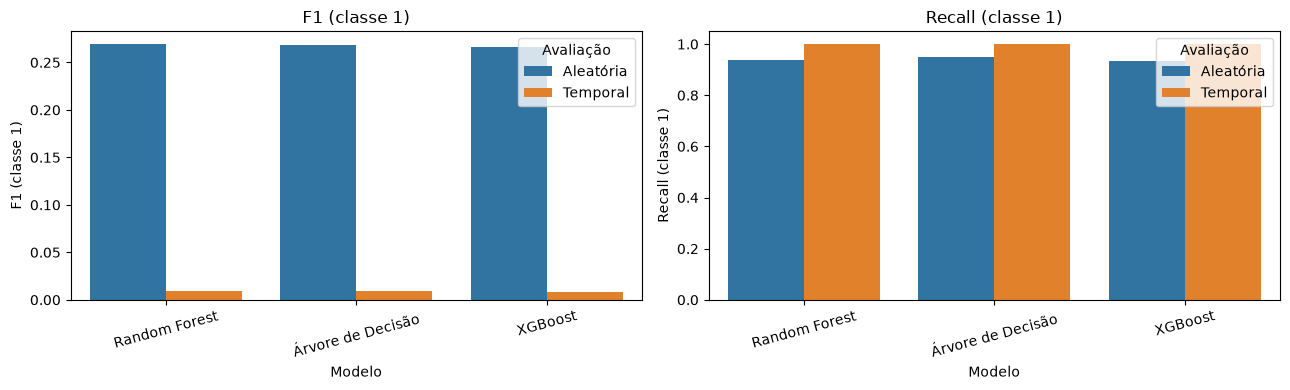

In [14]:
comparacao = pd.concat([
    tabela_resultados.assign(Avaliação="Aleatória"),
    tabela_temporal.assign(Avaliação="Temporal")
], ignore_index=True)
display(comparacao[[
    "Avaliação", "Modelo", "Acurácia", "Precisão (classe 1)",
    "Recall (classe 1)", "F1 (classe 1)", "Treino + ajuste (s)",
    "Predição do teste (s)"
]].round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metrica in zip(axes, ["F1 (classe 1)", "Recall (classe 1)"]):
    sns.barplot(data=comparacao, x="Modelo", y=metrica, hue="Avaliação", ax=ax)
    ax.tick_params(axis="x", rotation=15)
    ax.set_title(metrica)
plt.tight_layout()
plt.show()


## Falsos alarmes e falhas não detectadas

Um **falso positivo** é uma medição normal classificada como latência alta. Um **falso negativo** é uma medição de latência alta classificada como normal. Em monitoramento, o primeiro causa alarmes desnecessários; o segundo pode deixar passar um problema.


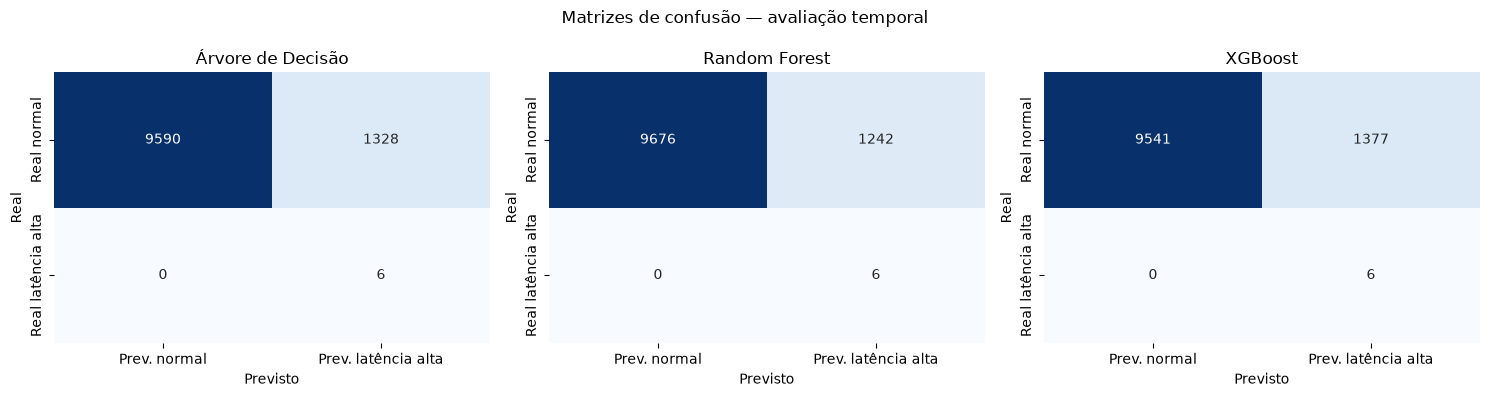

,Modelo,Falso positivo,Falso negativo,Verdadeiro positivo,Verdadeiro negativo
0,Árvore de Decisão,1328,0,6,9590
1,Random Forest,1242,0,6,9676
2,XGBoost,1377,0,6,9541


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nome, cm) in zip(axes, matrizes_t.items()):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Prev. normal", "Prev. latência alta"],
                yticklabels=["Real normal", "Real latência alta"])
    ax.set_title(nome)
    ax.set_xlabel("Previsto")
    ax.set_ylabel("Real")
plt.suptitle("Matrizes de confusão — avaliação temporal")
plt.tight_layout()
plt.show()
display(tabela_temporal[["Modelo", "Falso positivo", "Falso negativo",
                          "Verdadeiro positivo", "Verdadeiro negativo"]])


## Conclusão automática e arquivos para o artigo

A conclusão é gerada **após a execução**, com base no maior F1 temporal, maior recall e menor tempo de predição. Ela não substitui a discussão sobre interpretabilidade, custo dos erros e limitações.


In [16]:
vencedor_f1 = tabela_temporal.sort_values("F1 (classe 1)", ascending=False).iloc[0]
vencedor_recall = tabela_temporal.sort_values("Recall (classe 1)", ascending=False).iloc[0]
mais_rapido = tabela_temporal.sort_values("Predição do teste (s)").iloc[0]

print("CONCLUSÃO BASEADA NA AVALIAÇÃO TEMPORAL")
print(f"Maior F1: {vencedor_f1['Modelo']} ({vencedor_f1['F1 (classe 1)']:.4f}).")
print(f"Maior recall: {vencedor_recall['Modelo']} ({vencedor_recall['Recall (classe 1)']:.4f}).")
print(f"Predição mais rápida: {mais_rapido['Modelo']} ({mais_rapido['Predição do teste (s)']:.4f} s).")
for _, r in tabela_temporal.iterrows():
    print(f"{r['Modelo']}: {int(r['Falso positivo'])} falsos positivos; {int(r['Falso negativo'])} falsos negativos.")

print("\nTexto-base:")
print(
    f"Na avaliação temporal, {vencedor_f1['Modelo']} apresentou o maior F1 "
    f"({vencedor_f1['F1 (classe 1)']:.4f}) para a classe de latência alta. "
    f"{vencedor_recall['Modelo']} obteve o maior recall "
    f"({vencedor_recall['Recall (classe 1)']:.4f}). "
    "A decisão final deve ponderar esses resultados, os falsos alarmes, "
    "o tempo de predição e a interpretabilidade."
)

comparacao.to_csv("comparacao_aleatoria_temporal.csv", index=False, encoding="utf-8-sig")
tabela_temporal.to_csv("resultados_temporais.csv", index=False, encoding="utf-8-sig")
print("\nArquivos salvos: comparacao_aleatoria_temporal.csv, resultados_temporais.csv")


CONCLUSÃO BASEADA NA AVALIAÇÃO TEMPORAL
Maior F1: Random Forest (0.0096).
Maior recall: Árvore de Decisão (1.0000).
Predição mais rápida: Árvore de Decisão (0.0020 s).
Árvore de Decisão: 1328 falsos positivos; 0 falsos negativos.
Random Forest: 1242 falsos positivos; 0 falsos negativos.
XGBoost: 1377 falsos positivos; 0 falsos negativos.

Texto-base:
Na avaliação temporal, Random Forest apresentou o maior F1 (0.0096) para a classe de latência alta. Árvore de Decisão obteve o maior recall (1.0000). A decisão final deve ponderar esses resultados, os falsos alarmes, o tempo de predição e a interpretabilidade.

Arquivos salvos: comparacao_aleatoria_temporal.csv, resultados_temporais.csv


## Limitações para citar no artigo

- Os rótulos foram definidos por regras e podem não corresponder a falhas reais.
- Os dados vêm de uma rede residencial; o resultado não garante desempenho em outras redes.
- A classificação de latência alta na medição atual **não equivale** a prever degradação futura.
- As execuções de coleta podem se repetir nos períodos de treino e teste, embora os timestamps estejam separados.
- A avaliação temporal não utiliza o teste final para ajustar hiperparâmetros.
- As durações de treino e predição variam conforme o ambiente.

**Próxima evolução:** construir janelas anteriores e prever um rótulo em um instante futuro, mantendo a separação temporal.


In [17]:
import json
from pathlib import Path
comparacao.to_json("resultados_completos.json", orient="records", indent=2, force_ascii=False)
print("Resultados e ambiente registrados.")


Resultados e ambiente registrados.
